## 1. Imports and configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time, warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, GridSearchCV, learning_curve)
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             precision_score, recall_score, roc_auc_score,
                             confusion_matrix, classification_report)

RANDOM_STATE = 42
sns.set_style("whitegrid")
%matplotlib inline
np.random.seed(RANDOM_STATE)

# Model factories. A lighter forest is used only inside the CV-heavy sweeps
# (component sweep, grid search, learning curve) purely for speed; the final
# reported models use the full forest.
def make_lr():        return LogisticRegression(max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE)
def make_rf():        return RandomForestClassifier(n_estimators=250, min_samples_leaf=2,
                                                    class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)
def make_rf_light():  return RandomForestClassifier(n_estimators=120, min_samples_leaf=2,
                                                    class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)

def multiclass_scores(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Macro-Prec": precision_score(y_true, y_pred, average="macro"),
            "Macro-Recall": recall_score(y_true, y_pred, average="macro"),
            "Macro-F1": f1_score(y_true, y_pred, average="macro"),
            "Balanced-Acc": balanced_accuracy_score(y_true, y_pred)}

## 2. Load the dataset

The canonical source is the **UCI ML Repository, ID 270**. The official loader exposes only
the 128 features and gas labels:

```python
from ucimlrepo import fetch_ucirepo          # pip install ucimlrepo
ds = fetch_ucirepo(id=270)
X, y = ds.data.features, ds.data.targets
```

Our **sensor-drift study needs the batch index** (which acquisition month each sample came
from). We therefore read a public mirror of the same 13,910 measurements that additionally
preserves the `Batch ID` column, so the data is identical to UCI 270 but keeps the time
structure.

In [3]:
URL = ("https://raw.githubusercontent.com/HakanKARASU/"
       "Gas-Sensor-Array-Drift-Dataset/main/gas_sensor_data.csv")
df = pd.read_csv(URL)
FEATURES = [f"feature_{i}" for i in range(1, 129)]
print("Shape:", df.shape)
df[["Batch ID", "gas_label", "concentration"] + FEATURES[:3]].head()

Shape: (13910, 131)


,Batch ID,gas_label,concentration,feature_1,feature_2,feature_3
0,8,Acetaldehyde,30.0,12714.6680,2.126732,2.778869
1,8,Acetaldehyde,100.0,13124.5372,4.428956,2.751767
2,2,Acetaldehyde,50.0,4108.0312,1.333074,0.829559
3,8,Acetaldehyde,160.0,16628.4727,4.613198,3.810110
4,8,Acetaldehyde,140.0,2200.3432,1.623948,3.542865


## 3. Dataset description and audit

Recorded at the ChemoSignals Laboratory, UC San Diego, over **36 months (2008–2011)** with
**16 metal-oxide gas sensors**, each summarised by **8 features → 128 features** total.

- **Instances:** 13,910   **Features:** 128 continuous   **Target:** 6 gases
- **Batch ID:** 10 acquisition campaigns across the 36 months (used for the drift study)
- **Licence:** CC BY 4.0

*Citation: Vergara, A. et al. (2012). Gas Sensor Array Drift Dataset at Different
Concentrations. UCI ML Repository. https://doi.org/10.24432/C5MK6M*

A quick audit follows the Lab 02 pattern (types, missing values, duplicates, balance, scale).

In [4]:
audit = pd.DataFrame({
    "dtype": df[FEATURES].dtypes.astype(str).values,
}, index=FEATURES)
print("Missing values (whole table):", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nGas class counts:\n", df["gas_label"].value_counts())
print("\nSamples per batch:\n", df["Batch ID"].value_counts().sort_index())
print("\nFeature scale (min .. max): {:.0f} .. {:.0f}".format(
      df[FEATURES].values.min(), df[FEATURES].values.max()))
print("Most skewed features (|skew|):")
print(df[FEATURES].skew().abs().sort_values(ascending=False).head(5).round(2))

Missing values (whole table): 0
Duplicate rows: 0

Gas class counts:
 gas_label
Acetone         3009
Ethylene        2926
Ethanol         2565
Acetaldehyde    1936
Toluene         1833
Ammonia         1641
Name: count, dtype: int64

Samples per batch:
 Batch ID
1      445
2     3600
3     1244
4     1586
5      161
6      197
7     2300
8     3613
9      294
10     470
Name: count, dtype: int64

Feature scale (min .. max): -23661 .. 670687
Most skewed features (|skew|):
feature_42    117.93
feature_58    117.77
feature_50    117.28
feature_29     94.62
feature_10     88.79
dtype: float64


> **Audit read-out.** No missing values and no duplicate rows, so no imputation or
> de-duplication is required. The six classes are mildly imbalanced (so we will favour
> macro-averaged metrics), the 10 batches are very unevenly sized, and the features span
> roughly six orders of magnitude with heavy skew — which makes **standardisation essential**
> and motivates a **log transform**.

## 4. Exploratory data analysis

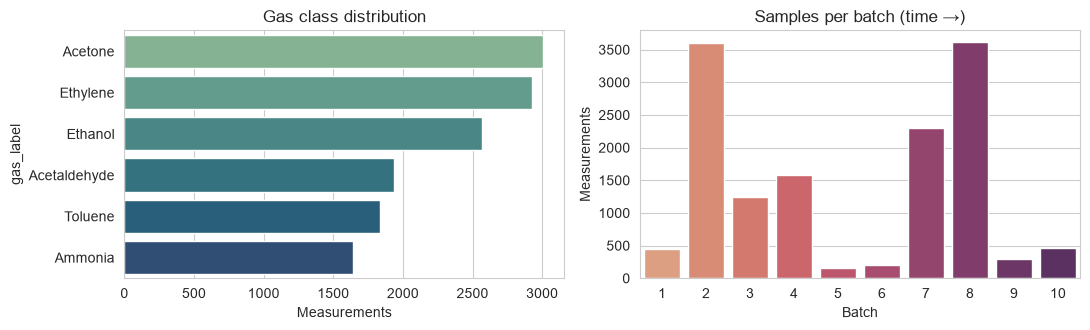

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
vc = df["gas_label"].value_counts()
sns.barplot(x=vc.values, y=vc.index, palette="crest", ax=ax[0])
ax[0].set_title("Gas class distribution"); ax[0].set_xlabel("Measurements")
bs = df["Batch ID"].value_counts().sort_index()
sns.barplot(x=bs.index, y=bs.values, palette="flare", ax=ax[1])
ax[1].set_title("Samples per batch (time \u2192)"); ax[1].set_xlabel("Batch"); ax[1].set_ylabel("Measurements")
plt.tight_layout(); plt.show()

## 5. Train/test split and scaling

A **stratified 75/25 split** keeps all six gases in proportion. Every transformation
(scaling, feature selection, PCA) is fit on the **training set only** to avoid leakage —
a point stressed throughout Lab 02 and Lab 11.

In [8]:
X = df[FEATURES].copy()
y = df["gas_label"].values
batch = df["Batch ID"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (10432, 128)  Test: (3478, 128)


### 5.1 Why standardisation matters - a measured demonstration

To show preprocessing is not cosmetic, we compare Logistic Regression **without** and
**with** standardisation. This is the first concrete step in *how accuracy is obtained*.

In [9]:
# Without scaling
lr_raw = make_lr().fit(X_train.values, y_train)
acc_noscale = accuracy_score(y_test, lr_raw.predict(X_test.values))

# With standardisation (fit on train only)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)
lr_scaled = make_lr().fit(X_train_s, y_train)
acc_scale = accuracy_score(y_test, lr_scaled.predict(X_test_s))

print(f"Logistic Regression WITHOUT scaling : {acc_noscale:.4f}")
print(f"Logistic Regression WITH scaling    : {acc_scale:.4f}")
print(f"Improvement from standardisation    : {acc_scale - acc_noscale:+.4f}")

Logistic Regression WITHOUT scaling : 0.9776
Logistic Regression WITH scaling    : 0.9899
Improvement from standardisation    : +0.0124


## 6. Feature engineering 
Feature engineering *creates* new, potentially more informative inputs. The 128 features are
laid out as **16 sensors × 8 features**. We add three principled groups:

1. **Signed-log transform** of every raw feature - tames the six-order-of-magnitude skew while
   preserving sign: `sign(x)·log(1+|x|)`.
2. **Per-sensor aggregates** - each sensor's mean and range across its 8 features (32 features),
   summarising each physical sensor's behaviour.
3. **Cross-sensor ratios** - each sensor-mean divided by the array-wide mean (16 features).
   Ratios cancel overall magnitude, which **drifts over time**, so they are a deliberately
   *drift-robust* representation - a direct link to the drift study later.

All three are **row-wise** (no information crosses between rows), so they introduce no leakage.

In [10]:
def engineer(frame):
    v = frame[FEATURES].values
    out = {}
    # 1. signed-log of each raw feature
    slog = np.sign(v) * np.log1p(np.abs(v))
    for i in range(128): out[f"slog_{i+1}"] = slog[:, i]
    # 2. per-sensor aggregates (16 sensors x 8 features)
    sensor_means = np.zeros((v.shape[0], 16))
    for s in range(16):
        block = v[:, s*8:(s+1)*8]
        sensor_means[:, s] = block.mean(axis=1)
        out[f"sensor{s+1}_mean"]  = block.mean(axis=1)
        out[f"sensor{s+1}_range"] = block.max(axis=1) - block.min(axis=1)
    # 3. cross-sensor ratios (sensor mean / array-wide mean)
    array_mean = sensor_means.mean(axis=1, keepdims=True)
    array_mean[array_mean == 0] = 1e-9
    for s in range(16):
        out[f"sensor{s+1}_ratio"] = sensor_means[:, s] / array_mean[:, 0]
    return pd.DataFrame(out, index=frame.index)

X_train_eng = engineer(X_train)
X_test_eng  = engineer(X_test)
print("Engineered feature count:", X_train_eng.shape[1],
      "(128 signed-log + 32 aggregates + 16 ratios)")
X_train_eng.iloc[:3, [0, 128, 129, 160]]

Engineered feature count: 176 (128 signed-log + 32 aggregates + 16 ratios)


,slog_1,sensor1_mean,sensor1_range,sensor1_ratio
3947,11.644161,14247.024529,114093.558989,3.592248
1018,10.148637,3196.092151,25563.943674,2.798330
6796,10.736675,5753.155805,46048.681388,2.242191


## 7. Feature selection 

Feature selection *chooses* which features to keep, using three taught techniques:
**correlation redundancy**, the **ANOVA F-test** (`f_classif`), and **Mutual Information**
(`mutual_info_classif`). Chi-square is not used — it is for categorical features and ours are
all continuous. Everything is computed on the **training set only**, and we keep the Lab 02
caveat in mind: *statistical significance is not the same as predictive usefulness*.

In [11]:
# Standardise the engineered features (fit on train only)
eng_scaler = StandardScaler().fit(X_train_eng)
Xtr_eng_s = pd.DataFrame(eng_scaler.transform(X_train_eng), columns=X_train_eng.columns, index=X_train_eng.index)
Xte_eng_s = pd.DataFrame(eng_scaler.transform(X_test_eng),  columns=X_test_eng.columns,  index=X_test_eng.index)

# 7a. correlation redundancy: drop one of any pair with |r| > 0.95
corr = np.corrcoef(Xtr_eng_s.values, rowvar=False)
keep_idx, dropped = [], set()
for i in range(corr.shape[0]):
    if i in dropped: continue
    keep_idx.append(i)
    for j in range(i+1, corr.shape[0]):
        if j not in dropped and abs(corr[i, j]) > 0.95:
            dropped.add(j)
kept_cols = Xtr_eng_s.columns[keep_idx]
print(f"After correlation filter: {len(kept_cols)} of {Xtr_eng_s.shape[1]} features kept")

After correlation filter: 59 of 176 features kept


In [12]:
# 7b. ANOVA F-test and 7c. Mutual Information on the correlation-filtered features
Xtr_k = Xtr_eng_s[kept_cols].values
f_scores, _ = f_classif(Xtr_k, y_train)
# MI on a stratified subsample for speed (ranking is stable); documented choice
sub = np.random.RandomState(RANDOM_STATE).permutation(len(y_train))[:4000]
mi_scores = mutual_info_classif(Xtr_k[sub], y_train[sub], random_state=RANDOM_STATE)

rank = pd.DataFrame({"feature": kept_cols,
                     "ANOVA_F": f_scores,
                     "MutualInfo": mi_scores})
rank["anova_rank"] = rank["ANOVA_F"].rank(ascending=False)
rank["mi_rank"]    = rank["MutualInfo"].rank(ascending=False)
rank["avg_rank"]   = rank[["anova_rank", "mi_rank"]].mean(axis=1)
rank = rank.sort_values("avg_rank")
TOP_K = 40
selected_cols = rank.head(TOP_K)["feature"].tolist()
print(f"Selected top {TOP_K} features by average ANOVA+MI rank.\n")
display(rank.head(10).round(4))

Selected top 40 features by average ANOVA+MI rank.



,feature,ANOVA_F,MutualInfo,anova_rank,mi_rank,avg_rank
49,sensor2_ratio,4164.3786,0.9394,2.0,1.0,1.5
51,sensor4_ratio,10465.4036,0.8700,1.0,2.0,1.5
56,sensor13_ratio,2279.0422,0.7743,7.0,4.0,5.5
42,sensor2_mean,2549.4568,0.7052,5.0,8.0,6.5
50,sensor3_ratio,2023.8660,0.8381,10.0,3.0,6.5
28,slog_69,4055.0761,0.6711,3.0,13.0,8.0
55,sensor11_ratio,1493.1116,0.7605,13.0,5.0,9.0
7,slog_11,2898.1299,0.6028,4.0,18.0,11.0
53,sensor6_ratio,1458.5135,0.7165,16.0,7.0,11.5
26,slog_65,1414.3205,0.7176,18.0,6.0,12.0


## 8. Dimensionality reduction with PCA 

PCA re-expresses the standardised features as uncorrelated components ordered by variance.
We follow the Lab 11 workflow: explained-variance curve, a 95% cut, a 2-component view, and a
component sweep validated with cross-validation.

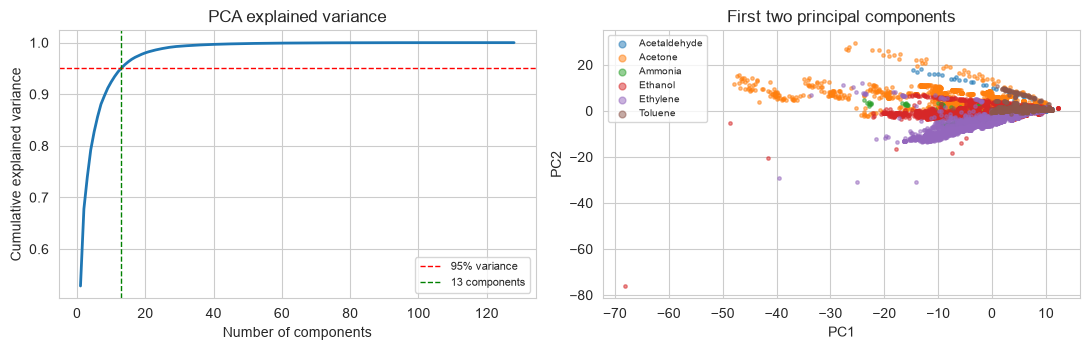

13 components capture 95% of the variance (from 128 features).


In [13]:
pca_full = PCA().fit(X_train_s)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.argmax(cum >= 0.95) + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(range(1, len(cum)+1), cum, lw=2)
ax[0].axhline(0.95, color="r", ls="--", lw=1, label="95% variance")
ax[0].axvline(n95, color="g", ls="--", lw=1, label=f"{n95} components")
ax[0].set_xlabel("Number of components"); ax[0].set_ylabel("Cumulative explained variance")
ax[0].set_title("PCA explained variance"); ax[0].legend(fontsize=8)

p2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_train_s)
for g in np.unique(y_train):
    m = y_train == g
    ax[1].scatter(p2[m, 0], p2[m, 1], s=6, alpha=.5, label=g)
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].set_title("First two principal components")
ax[1].legend(fontsize=7, markerscale=2)
plt.tight_layout(); plt.show()
print(f"{n95} components capture 95% of the variance (from 128 features).")

In [14]:
# Prepare the four feature representations (all fit on train only)
# 1. All standardised features
# 2. Engineered + selected features
# 3. PCA 95%
pca95 = PCA(n_components=0.95, random_state=RANDOM_STATE).fit(X_train_s)
Xtr_pca, Xte_pca = pca95.transform(X_train_s), pca95.transform(X_test_s)

representations = {
    "All (128)":        (X_train_s,                       X_test_s),
    "Engineered+Select":(Xtr_eng_s[selected_cols].values, Xte_eng_s[selected_cols].values),
    "PCA-95%":          (Xtr_pca,                         Xte_pca),
}
for k, (a, _) in representations.items():
    print(f"{k:20s}: {a.shape[1]} features")

All (128)           : 128 features
Engineered+Select   : 40 features
PCA-95%             : 13 features


## 9. Why these two algorithms? - a six-model screen

Before committing, we screen six classical algorithms (Labs 05–09) on the PCA features and
use the result to **justify** the choice. Only two are carried forward as the headline pair.